In [ ]:
# This makes a dark and bad pixel frame for the Procyon 2023B data

# Created by E.S., 2018 October

In [1]:
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from astropy.io import fits
#import sys
import glob, os
%matplotlib inline

In [2]:
stem_read = '/data/procyon_fizeau_2023B/raw_data/lm_240131/' # read the raw frames
stem_write = '/data/procyon_fizeau_2023B/calib_files/sandbox/' # write the dark frame

In [3]:
# darks are frames 11801 to 12800
nums_of_interest = np.arange(11801,12800,1)

# these are just one readout per FITS file, so the 'slopes' are as-is
cube_flat_slopes = np.zeros((len(nums_of_interest),512,2048))

for i in range(0,len(nums_of_interest)):

    file_basename = f'lm_240131_{int(nums_of_interest[i]):06d}.fits'
                                         
    print(file_basename)

    hdul = fits.open(stem_read + file_basename)            
    cube_flat_slopes[i,:,:] = hdul[0].data
                                         
    

lm_240131_011801.fits
lm_240131_011802.fits
lm_240131_011803.fits
lm_240131_011804.fits
lm_240131_011805.fits
lm_240131_011806.fits
lm_240131_011807.fits
lm_240131_011808.fits
lm_240131_011809.fits
lm_240131_011810.fits
lm_240131_011811.fits
lm_240131_011812.fits
lm_240131_011813.fits
lm_240131_011814.fits
lm_240131_011815.fits
lm_240131_011816.fits
lm_240131_011817.fits
lm_240131_011818.fits
lm_240131_011819.fits
lm_240131_011820.fits
lm_240131_011821.fits
lm_240131_011822.fits
lm_240131_011823.fits
lm_240131_011824.fits
lm_240131_011825.fits
lm_240131_011826.fits
lm_240131_011827.fits
lm_240131_011828.fits
lm_240131_011829.fits
lm_240131_011830.fits
lm_240131_011831.fits
lm_240131_011832.fits
lm_240131_011833.fits
lm_240131_011834.fits
lm_240131_011835.fits
lm_240131_011836.fits
lm_240131_011837.fits
lm_240131_011838.fits
lm_240131_011839.fits
lm_240131_011840.fits
lm_240131_011841.fits
lm_240131_011842.fits
lm_240131_011843.fits
lm_240131_011844.fits
lm_240131_011845.fits
lm_240131_

In [ ]:
# check type

#data = hdul[0].data
#print(data.dtype, data.min(), data.max())

uint16 0 3461


In [5]:
# write dark

# write mean to file (note that the mean operation makes the data go from ints to floats)
master_dark = np.mean(cube_flat_slopes, axis=0)

fits.writeto(stem_write + 'master_dark_procyon_2023B.fits', master_dark, overwrite=True)

In [6]:
type(master_dark)
type(master_dark[0][0])

numpy.float64

In [ ]:
# pixels with counts <three_sig_neg (~190) or >three_sig_pos (750) in the mean



std of master dark: 93.39749290009522
median of master dark: 471.6226226226226
median +3 std of master dark: 751.8151013229083
median -3 std of master dark: 191.43014392233698


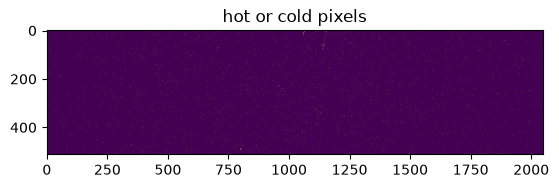

number of hot or cold pixels: 4524
fraction of hot or cold pixels: 0.004314422607421875


In [35]:
# hot and cold pixels

print('std of master dark:', np.std(master_dark))
print('median of master dark:', np.median(master_dark))

print('median +3 std of master dark:', np.median(master_dark) + 3 * np.std(master_dark))
print('median -3 std of master dark:', np.median(master_dark) - 3 * np.std(master_dark))

three_sig_pos = np.median(master_dark) + 3 * np.std(master_dark)
three_sig_neg = np.median(master_dark) - 3 * np.std(master_dark)

hot_cold_pixels = (master_dark < three_sig_neg) | (master_dark > three_sig_pos)

plt.imshow(hot_cold_pixels)
plt.title('hot or cold pixels')
plt.show()

print('number of hot or cold pixels:', np.sum(hot_cold_pixels))
print('fraction of hot or cold pixels:', np.sum(hot_cold_pixels) / master_dark.size)

# write as FITS file
fits.writeto(stem_write + 'junk_hot_cold_pixels_procyon_2023B.fits', np.int16(hot_cold_pixels), overwrite=True)

In [13]:
stdev_all = np.std(cube_flat_slopes, axis=0)

# write as FITS file
fits.writeto(stem_write + 'junk_stdev_all_procyon_2023B.fits', stdev_all, overwrite=True)

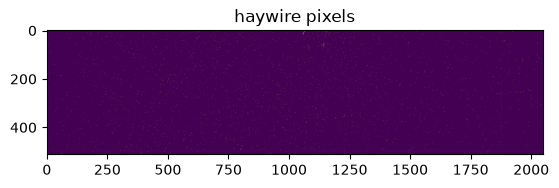

number of haywire pixels: 3181
fraction of haywire pixels: 0.0030336380004882812


In [38]:
# haywire pixels
# flag pixels in the stdev frame that are >3 (absolute value)

haywire_pixels = np.abs(stdev_all) > 3

plt.imshow(haywire_pixels)
plt.title('haywire pixels')
plt.show()

print('number of haywire pixels:', np.sum(haywire_pixels))
print('fraction of haywire pixels:', np.sum(haywire_pixels) / stdev_all.size)

# write as FITS file
fits.writeto(stem_write + 'junk_haywire_pixels_procyon_2023B.fits', np.int16(haywire_pixels), overwrite=True)

# write the bad pixel frame
#bad_pixel_frame = master_dark.copy()
#bad_pixel_frame[haywire_pixels] = 0

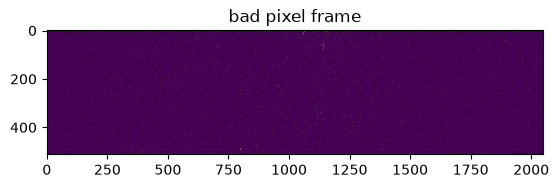

number of bad pixels: 5718
fraction of bad pixels: 0.0054531097412109375


In [39]:
# union of hot, cold, and haywire pixels:
bad_pixel_frame = hot_cold_pixels | haywire_pixels
plt.imshow(bad_pixel_frame)
plt.title('bad pixel frame')
plt.show()

print('number of bad pixels:', np.sum(bad_pixel_frame))
print('fraction of bad pixels:', np.sum(bad_pixel_frame) / master_dark.size)

# write as FITS file
fits.writeto(stem_write + 'junk_bad_pixel_frame_procyon_2023B.fits', np.int16(bad_pixel_frame), overwrite=True)


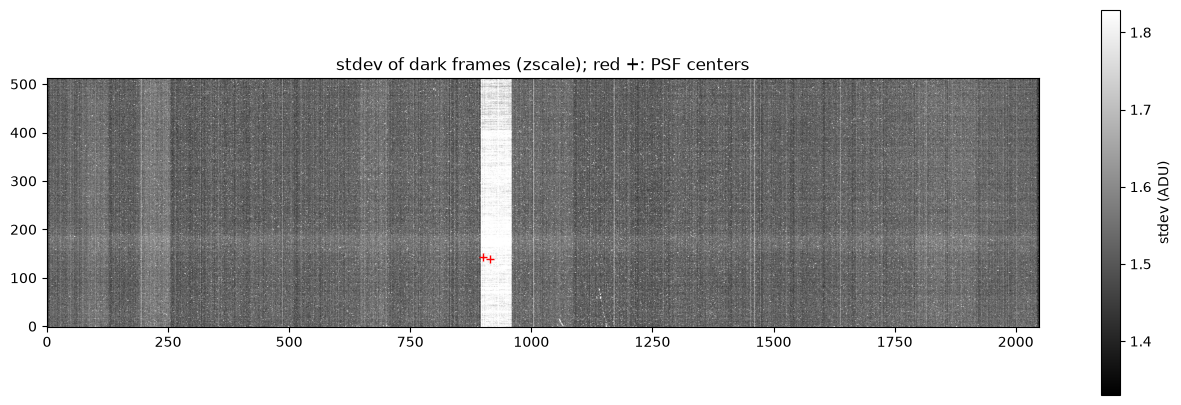

In [22]:
# stdev frame with zscale; red + marks the approximate PSF centers from the blocks CSV
from astropy.visualization import ZScaleInterval, ImageNormalize

blocks = pd.read_csv('../scripts/config_files/datasets/procyon_240131_blocks.csv', comment='#')
psf_pos = blocks.dropna(subset=['star_y', 'star_x'])[['star_y', 'star_x']].drop_duplicates()

norm = ImageNormalize(stdev_all, interval=ZScaleInterval())

plt.figure(figsize=(16, 5))
im = plt.imshow(stdev_all, origin='lower', cmap='gray', norm=norm)
plt.scatter(psf_pos['star_x'], psf_pos['star_y'], marker='+', c='red', s=40, linewidths=1)
plt.colorbar(im, label='stdev (ADU)')
plt.title('stdev of dark frames (zscale); red +: PSF centers')
plt.show()


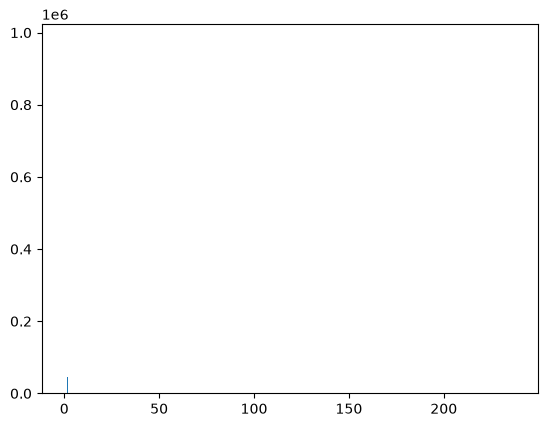

In [12]:
plt.hist(stdev_all.flatten(), bins=1000)
plt.show()